## 1. Установка

Запускайте ячейки сверху вниз в Jupyter или Google Colab с Python 3.11+. При первом запуске нужны интернет и место для открытой модели и CIFAR-10; регистрация и токен Hugging Face не нужны.

Результаты выполнения сохранены: примеры изображений и поиска видны сразу при открытии ноутбука. Для своих запросов выполните ячейки сверху вниз.


## 2. Импорты и устройство

Выбираем CUDA, затем MPS на Apple Silicon, иначе CPU. Модель работает в FP32; поиск по готовым векторам выполняется на CPU.


In [ ]:
import random

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torchvision.datasets import CIFAR10
from transformers import AutoProcessor, CLIPModel

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)


Device: mps


## 3. Датасет

Берём по 15 случайных изображений каждого из 10 классов тестовой выборки с seed = 42. Метки используем только для отбора и подписей, а в поиск передаём изображения без меток. CIFAR-10 содержит изображения 32 × 32, поэтому результаты CLIP могут быть неидеальными.


In [3]:
dataset = CIFAR10(root="./data", train=False, download=True)
rng = random.Random(42)
selected_indices = []
for class_id in range(10):
    candidates = [i for i, label in enumerate(dataset.targets) if label == class_id]
    selected_indices.extend(rng.sample(candidates, 15))
rng.shuffle(selected_indices)
images, labels = zip(*(dataset[i] for i in selected_indices))
images, labels = list(images), list(labels)
print(f"Images: {len(images)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5), layout="constrained")
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(image)
    ax.set_title(dataset.classes[label])
    ax.axis("off")
plt.show()


  0%|          | 688k/170M [00:08<32:58, 85.8kB/s] 


KeyboardInterrupt: 

## 4. Модель CLIP

- CLIP (Contrastive Language-Image Pre-training) — модель, сопоставляющая текст и изображения в общем пространстве векторов.
- Image Encoder — модель преобразования изображения в вектор.
- Text Encoder — модель преобразования текста в вектор.
- Embedding — числовое представление объекта.
- Cosine Similarity — мера сходства направлений векторов.

У этой модели визуальный энкодер — Vision Transformer: процессор приводит изображение к 224 × 224, а ViT делит его на патчи 32 × 32. Используем предобученные веса без обучения; в [Transformers 4.57.6](https://github.com/huggingface/transformers/blob/v4.57.6/src/transformers/models/clip/modeling_clip.py) методы `get_image_features()` и `get_text_features()` возвращают тензоры.


In [ ]:
model_id = "openai/clip-vit-base-patch32"
processor = AutoProcessor.from_pretrained(model_id, use_fast=False)
model = CLIPModel.from_pretrained(model_id, use_safetensors=True).to(device)
model.eval();


## 5. Эмбеддинги изображений

Индексируем 150 изображений один раз, пакетами по 16. Получаем `[150, 512]`: по одному вектору на изображение, с размерностью 512, заданной проекцией CLIP. Нормализация делает длину вектора единичной, поэтому скалярное произведение равно косинусному сходству; готовый индекс остаётся в памяти CPU.


In [ ]:
batch_size = 16
embedding_batches = []
with torch.inference_mode():
    for start in range(0, len(images), batch_size):
        inputs = processor(images=images[start:start + batch_size], return_tensors="pt").to(device)
        features = model.get_image_features(**inputs)
        embedding_batches.append(F.normalize(features, dim=-1).cpu())
image_embeddings = torch.cat(embedding_batches)
print(image_embeddings.shape)


torch.Size([150, 512])


## 6. Поиск по тексту

Введите запрос на английском и перезапустите вызов функции. Под результатами показаны класс и cosine similarity с тремя десятичными знаками; это сходство, а не вероятность. Для этой коллекции используйте `top_k` от 1 до 150.

Например, запрос `a photo of a cat` ниже выдаёт пять картинок: над подборкой указан запрос, под каждой картинкой — класс и оценка сходства. Чем выше оценка, тем ближе изображение к запросу по представлениям CLIP.

Чтобы попробовать свой запрос после выполнения ячеек, измените текст в вызове:

```python
search_text("a photo of a cat", top_k=5)
```


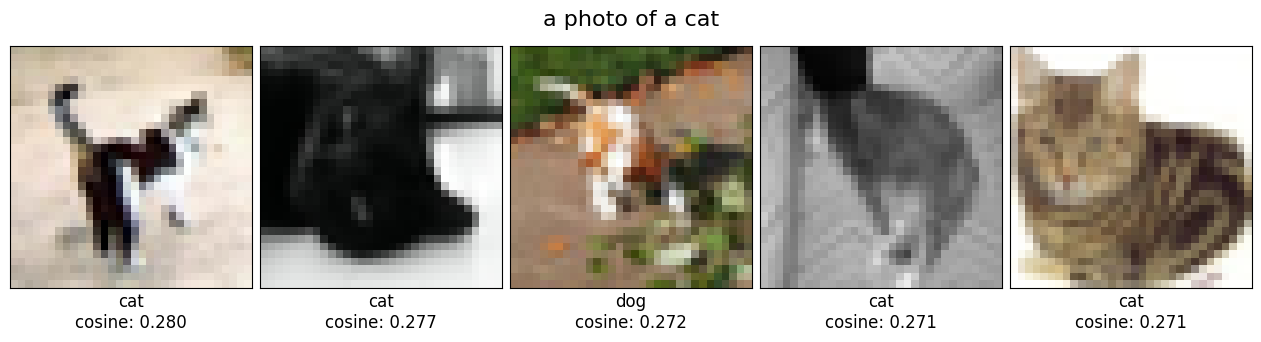

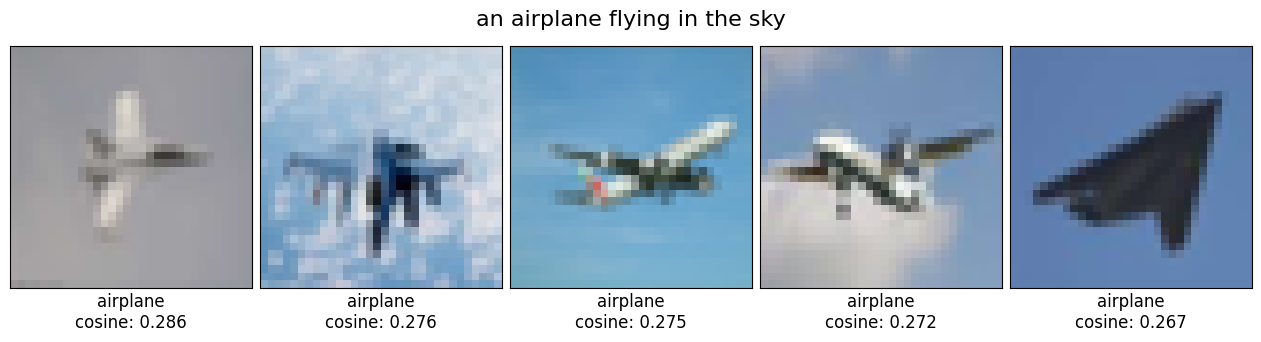

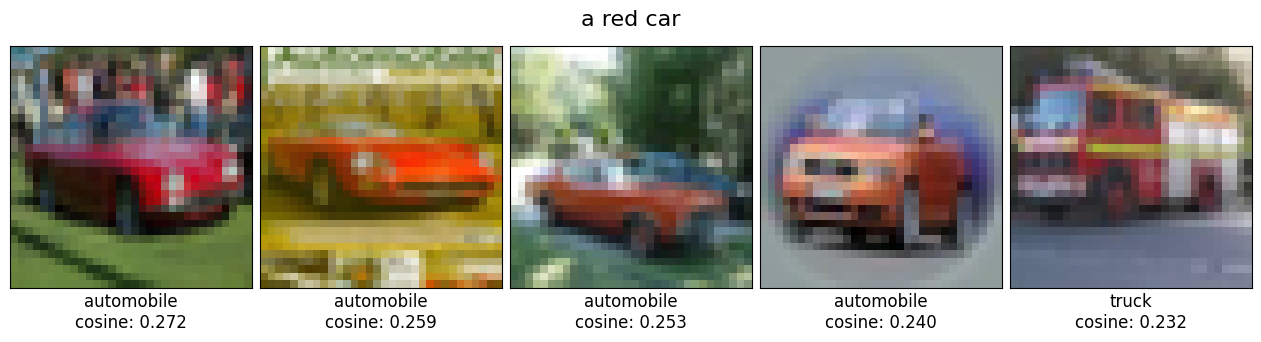

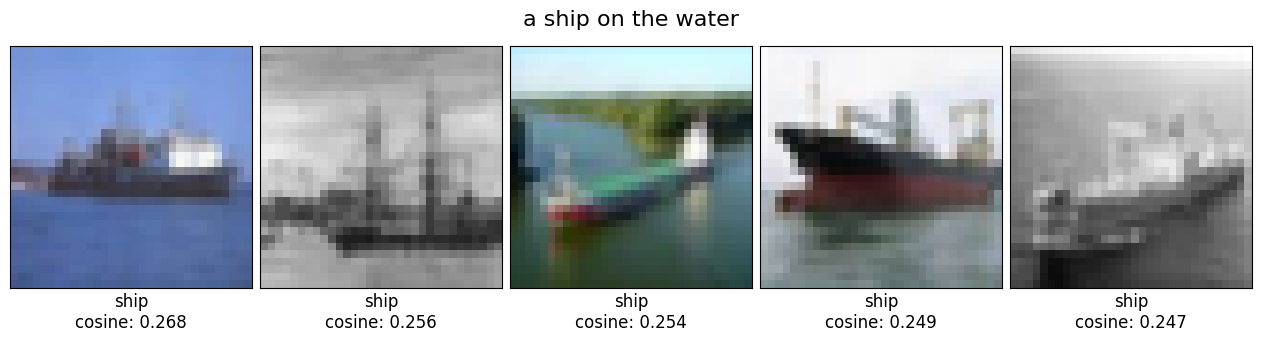

In [ ]:
@torch.inference_mode()
def search_text(query, top_k=5):
    inputs = processor(text=[query], return_tensors="pt", padding=True, truncation=True).to(device)
    features = model.get_text_features(**inputs)
    text_embedding = F.normalize(features, dim=-1).cpu()
    scores = (text_embedding @ image_embeddings.T).squeeze(0)
    values, indices = scores.topk(top_k)

    fig, axes = plt.subplots(1, top_k, figsize=(2.5 * top_k, 3.2), squeeze=False, layout="constrained")
    fig.suptitle(query, fontsize=16)
    for ax, idx, score in zip(axes.flat, indices.tolist(), values.tolist()):
        ax.imshow(images[idx])
        ax.set_xlabel(f"{dataset.classes[labels[idx]]}\ncosine: {score:.3f}", fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])
    plt.show()

search_text("a photo of a cat")
search_text("an airplane flying in the sky")
search_text("a red car")
search_text("a ship on the water")


## 7. Поиск похожих изображений

Слева — исходное изображение, справа — ближайшие соседи без самого исходного изображения. Используем готовые эмбеддинги, без повторного запуска энкодера. Выбирайте `image_idx` от 0 до 149 и `top_k` от 1 до 149.


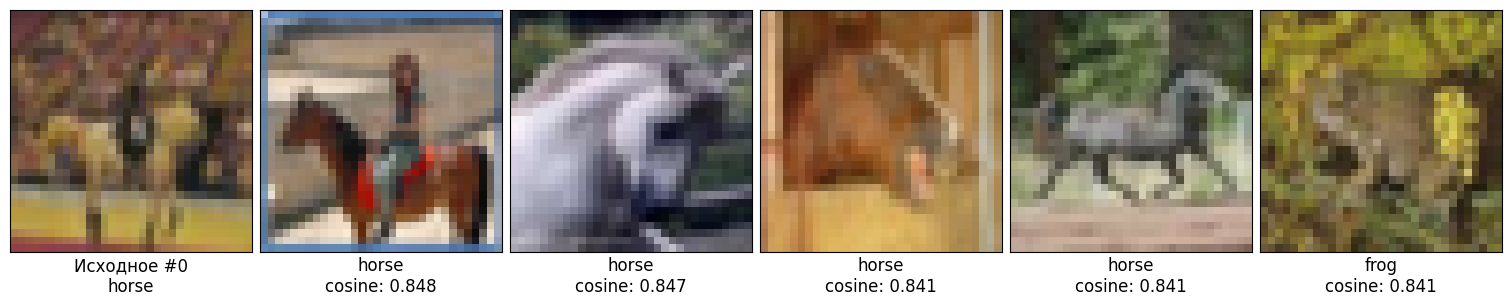

In [ ]:
def search_image(image_idx=0, top_k=5):
    scores = image_embeddings[image_idx] @ image_embeddings.T
    scores[image_idx] = -torch.inf
    values, indices = scores.topk(top_k)

    fig, axes = plt.subplots(1, top_k + 1, figsize=(2.5 * (top_k + 1), 3.2), layout="constrained")
    axes[0].imshow(images[image_idx])
    axes[0].set_xlabel(f"Исходное #{image_idx}\n{dataset.classes[labels[image_idx]]}", fontsize=12)
    for ax, idx, score in zip(axes[1:], indices.tolist(), values.tolist()):
        ax.imshow(images[idx])
        ax.set_xlabel(f"{dataset.classes[labels[idx]]}\ncosine: {score:.3f}", fontsize=12)
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
    plt.show()

search_image(image_idx=0)


## 8. Зависимость от формулировки

Разные описания дают разные текстовые векторы и могут менять результаты поиска. Сравните три формулировки, не меняя коллекцию изображений.


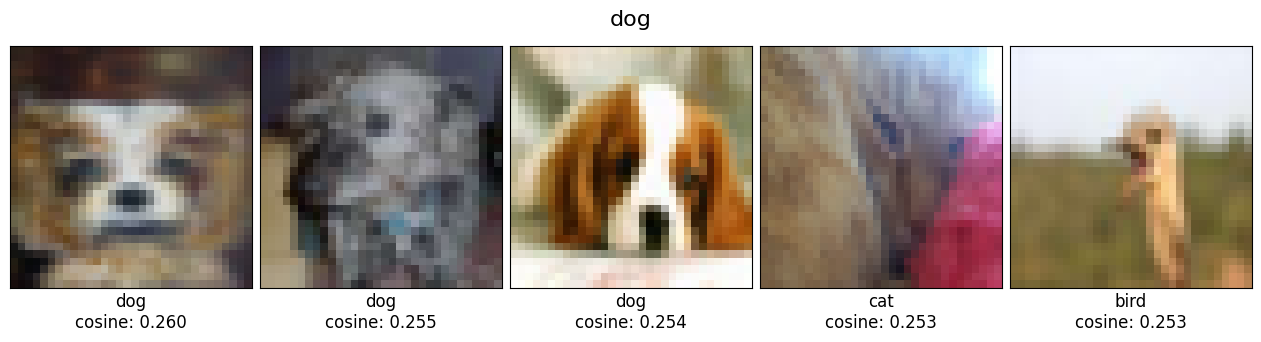

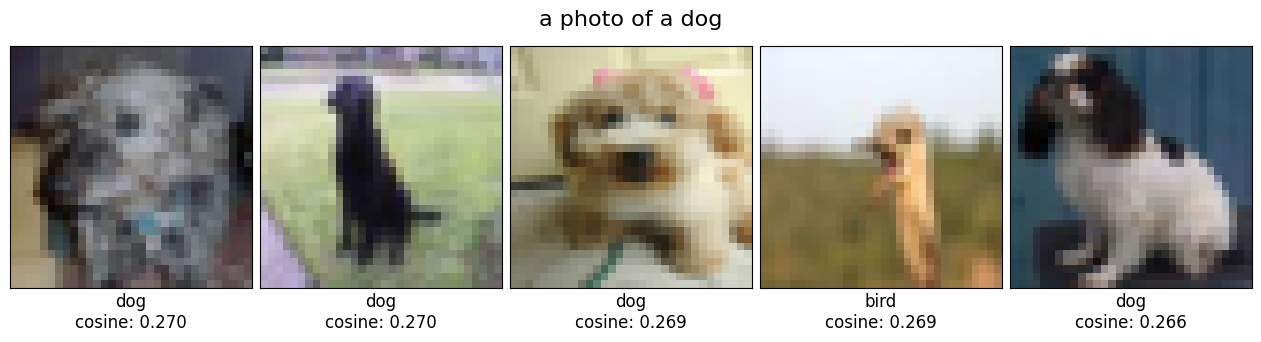

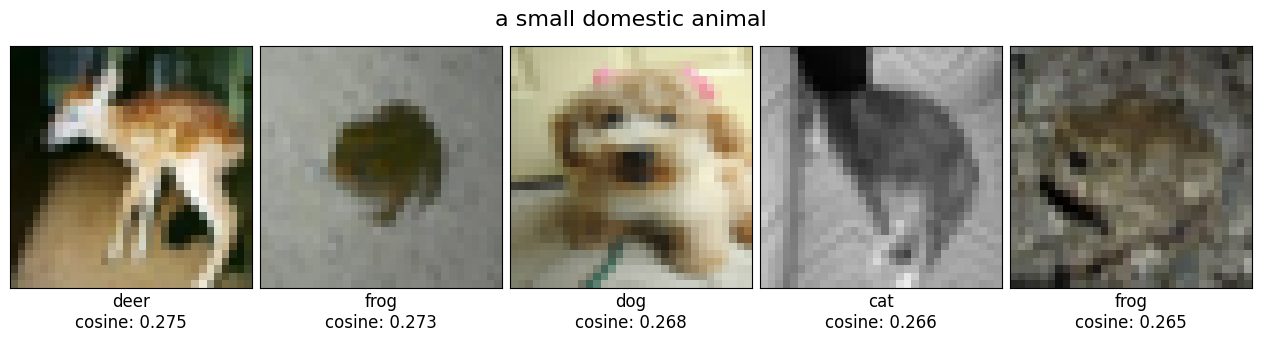

In [ ]:
search_text("dog")
search_text("a photo of a dog")
search_text("a small domestic animal")
